In [2]:
from pathlib import Path

import numpy as np
import pandas as pd

In [3]:
DATA_PATH = Path.cwd().parent / "data"
BARCELONA_DATA_PATH = "PBC_dataset_normal_DIB"
MUNICH_DATA_PATH = "PKG-AML-Cytomorphology_LMU"
ABBREVIATIONS = DATA_PATH / MUNICH_DATA_PATH / "abbreviations.txt"
DATASET_PATHS = {
    "barcelona": DATA_PATH / BARCELONA_DATA_PATH,
    "munich": DATA_PATH / MUNICH_DATA_PATH,
}
BARCELONA_DICT = {
    "BA": "Basophil",
    "EO": "Eosinophil",
    "ERB": "Erythroblast",
    "MMY": "Metamyelocyte",
    "MY": "Myelocyte",
    "PMY": "Promyelocyte",
    "LY": "Lymphocyte",
    "MO": "Monocyte",
    "BNE": "Neutrophil (band)",
    "SNE": "Neutrophil (segmented)",
    "PLATELET": "Platelet",
}
MUNICH_DICT = {
    "BAS": "basophil",
    "EBO": "erythroblast",
    "EOS": "eosinophil",
    "LYA": "Lymphocyte",
    "LYT": "Lymphocyte",
    "MMZ": "Metamyelocyte",
    "MON": "Monocyte",
    "MYB": "Myelocyte",
    "MYO": "Myeloblast",
    "NGB": "Neutrophil (band)",
    "NGS": "Neutrophil (segmented)",
    "PMB": "Promyelocyte",
    "PMO": "Promyelocyte",
}
MAPPING_DICT = {"barcelona": BARCELONA_DICT, "munich": MUNICH_DICT}
CELL_TYPE_TO_IDX = {
    name: i for i, name in enumerate(set(BARCELONA_DICT.values()) | set(MUNICH_DICT.values()))
}
DATASET_TO_IDX = {"barcelona": 0, "munich": 1}

IMG_SIZE = (224, 224)  # (H, W)

In [4]:
def get_images(data_dir: str, dataset_name: str) -> list[tuple[str, str, str]]:
    """Renvoie une liste de tuple contenant les chemins vers les images, le dataset et le type originel."""
    data_path = Path(data_dir)
    image_paths = (
        list(data_path.glob("**/*.jpg"))
        + list(data_path.glob("**/*.png"))
        + list(data_path.glob("**/*.tiff"))
    )
    labels = [p.stem.split("_")[0] for p in image_paths]
    print(set(labels))
    return [(str(p), dataset_name, label) for p, label in zip(image_paths, labels)]

In [5]:
barcelona_df = pd.DataFrame(
    get_images(DATA_PATH / BARCELONA_DATA_PATH, "barcelona"),
    columns=["path", "dataset", "original_type"],
)
barcelona_df.head()

{'PLATELET', 'IG', 'EO', 'LY', 'MMY', 'SNE', 'MO', 'ERB', 'PMY', 'MY', 'BNE', 'NEUTROPHIL', 'BA'}


,path,dataset,original_type
0,/Users/romain/Projects/Liora/Projet/jul26_bds_...,barcelona,BA
1,/Users/romain/Projects/Liora/Projet/jul26_bds_...,barcelona,BA
2,/Users/romain/Projects/Liora/Projet/jul26_bds_...,barcelona,BA
3,/Users/romain/Projects/Liora/Projet/jul26_bds_...,barcelona,BA
4,/Users/romain/Projects/Liora/Projet/jul26_bds_...,barcelona,BA


In [6]:
munich_df = pd.DataFrame(
    get_images(DATA_PATH / MUNICH_DATA_PATH, "munich"), columns=["path", "dataset", "original_type"]
)

{'MOB', 'NGS', 'PMB', 'MYO', 'KSC', 'MMZ', 'PMO', 'NGB', 'LYA', 'EOS', 'EBO', 'BAS', 'MYB', 'MON', 'LYT'}


In [7]:
new_df = pd.concat([munich_df, barcelona_df], ignore_index=True)
new_df["type"] = new_df.apply(
    lambda row: MAPPING_DICT[row.dataset].get(row.original_type, np.nan), axis=1
)
new_df.sample(5)

,path,dataset,original_type,type
28504,/Users/romain/Projects/Liora/Projet/jul26_bds_...,barcelona,EO,Eosinophil
5779,/Users/romain/Projects/Liora/Projet/jul26_bds_...,munich,NGS,Neutrophil (segmented)
27275,/Users/romain/Projects/Liora/Projet/jul26_bds_...,barcelona,EO,Eosinophil
20599,/Users/romain/Projects/Liora/Projet/jul26_bds_...,barcelona,SNE,Neutrophil (segmented)
2864,/Users/romain/Projects/Liora/Projet/jul26_bds_...,munich,MYO,Myeloblast


In [8]:
new_df.groupby(["dataset", "type"])["path"].count()

dataset    type                  
barcelona  Basophil                  1218
           Eosinophil                3117
           Erythroblast              1551
           Lymphocyte                1214
           Metamyelocyte             1015
           Monocyte                  1420
           Myelocyte                 1137
           Neutrophil (band)         1633
           Neutrophil (segmented)    1646
           Platelet                  2348
           Promyelocyte               592
munich     Lymphocyte                3948
           Metamyelocyte               15
           Monocyte                  1789
           Myeloblast                3268
           Myelocyte                   42
           Neutrophil (band)          109
           Neutrophil (segmented)    8484
           Promyelocyte                88
           basophil                    79
           eosinophil                 424
           erythroblast                78
Name: path, dtype: int64

In [9]:
new_df.groupby(["dataset", "original_type"])["path"].count()

dataset    original_type
barcelona  BA               1218
           BNE              1633
           EO               3117
           ERB              1551
           IG                151
           LY               1214
           MMY              1015
           MO               1420
           MY               1137
           NEUTROPHIL         50
           PLATELET         2348
           PMY               592
           SNE              1646
munich     BAS                79
           EBO                78
           EOS               424
           KSC                15
           LYA                11
           LYT              3937
           MMZ                15
           MOB                26
           MON              1789
           MYB                42
           MYO              3268
           NGB               109
           NGS              8484
           PMB                18
           PMO                70
Name: path, dtype: int64

In [10]:
def create_dataframe(
    use_dataset: str = "all",
    nb_images: int = 0,
    stratify: str = "no",
    classs: str = "type",
):
    """Retrieve images path and store source dataset, original and final types, label and criticality in a DataFrame."""
    data = []
    if use_dataset in ["all", "barcelona"]:
        data.extend(get_images(DATASET_PATHS["barcelona"], "barcelona"))
    if use_dataset in ["all", "munich"]:
        data.extend(get_images(DATASET_PATHS["munich"], "munich"))
    df = pd.DataFrame(data, columns=["path", "dataset", "original_type"])

    update_data = make_update_data(classs)
    df[["type", "label", "criticality", "type_dataset"]] = df.apply(
        update_data, axis=1, result_type="expand"
    )
    df = df.dropna()

    if nb_images > 0 and stratify != "no":
        n = nb_images // df[stratify].nunique()
        return (
            df.groupby(stratify, group_keys=False)[df.columns]
            .apply(lambda g: g.sample(n=min(len(g), n)))
            .reset_index(drop=True)
        )
    if nb_images > 0:
        return df.sample(nb_images).reset_index(drop=True)
    return df

In [11]:
def make_update_data(classs: str = "type"):
    def update_data(row):
        """Update data with final type, label, criticality and type_dataset."""
        type_ = MAPPING_DICT[row.dataset].get(row.original_type)
        if type_ is None:
            return (None, None, None, None)
        criticality = "normal"
        label = CELL_TYPE_TO_IDX[type_]
        return type_, label, criticality, type_ + "_" + row.dataset

    return update_data

In [12]:
df = create_dataframe(nb_images=2000, stratify="dataset")
print(df.shape)
df.head()

{'PLATELET', 'IG', 'EO', 'LY', 'MMY', 'SNE', 'MO', 'ERB', 'PMY', 'MY', 'BNE', 'NEUTROPHIL', 'BA'}
{'MOB', 'NGS', 'PMB', 'MYO', 'KSC', 'MMZ', 'PMO', 'NGB', 'LYA', 'EOS', 'EBO', 'BAS', 'MYB', 'MON', 'LYT'}
(2000, 7)


,path,dataset,original_type,type,label,criticality,type_dataset
0,/Users/romain/Projects/Liora/Projet/jul26_bds_...,barcelona,BNE,Neutrophil (band),12.0,normal,Neutrophil (band)_barcelona
1,/Users/romain/Projects/Liora/Projet/jul26_bds_...,barcelona,MY,Myelocyte,5.0,normal,Myelocyte_barcelona
2,/Users/romain/Projects/Liora/Projet/jul26_bds_...,barcelona,EO,Eosinophil,10.0,normal,Eosinophil_barcelona
3,/Users/romain/Projects/Liora/Projet/jul26_bds_...,barcelona,MO,Monocyte,7.0,normal,Monocyte_barcelona
4,/Users/romain/Projects/Liora/Projet/jul26_bds_...,barcelona,BNE,Neutrophil (band),12.0,normal,Neutrophil (band)_barcelona


In [45]:
df.dataset.value_counts()

dataset
barcelona    1000
munich       1000
Name: count, dtype: int64

In [4]:
import sys
from pathlib import Path

# project root = parent of notebooks/
sys.path.insert(0, str(Path.cwd().parent))

from src.features.transform import build_transform

ModuleNotFoundError: No module named 'constants'

In [13]:
import torch
import torchstain

In [14]:
normalizer = torchstain.normalizers.ReinhardNormalizer(backend="torch")
normalizer.target_means = np.array([79.3602, 12.1453, -1.5495])
normalizer.target_stds = np.array([16.9211, 13.2902, 16.5128])

In [15]:
dataset_mean = np.array([0.6001, 0.5036, 0.5408])
dataset_std = np.array([0.2312, 0.2576, 0.2105])

In [ ]:
transform = build_transform(
    training=False,
    img_size=(224, 224),
    # dataset_mean=torch.zeros(3),
    # dataset_std=torch.ones(3),
    dataset_mean=dataset_mean,
    dataset_std=dataset_std,
    reinhard_normalizer=normalizer,
    use_clahe=True,
    clahe_clip_limit=2.0,
)


In [17]:
def to_hwc(t):
    t = t.detach().cpu().float()
    if t.shape[0] in (1, 3):  # CHW -> HWC
        t = t.permute(1, 2, 0)
    if t.max() > 1.5:  # uint8 -> [0,1]
        t = t / 255.0
    return t.clamp(0, 1).numpy()


/Users/romain/Projects/Liora/Projet/jul26_bds_blood_cells/data/PKG-AML-Cytomorphology_LMU/NGS/NGS_3836.tiff


/var/folders/m_/b04ywwq12g933cgpc9bdd6jm0000gn/T/ipykernel_55605/859262855.py:12: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  out = (out * dataset_std[:, None, None] + dataset_mean[:, None, None]).clamp(0, 1)


(np.float64(-0.5), np.float64(223.5), np.float64(223.5), np.float64(-0.5))

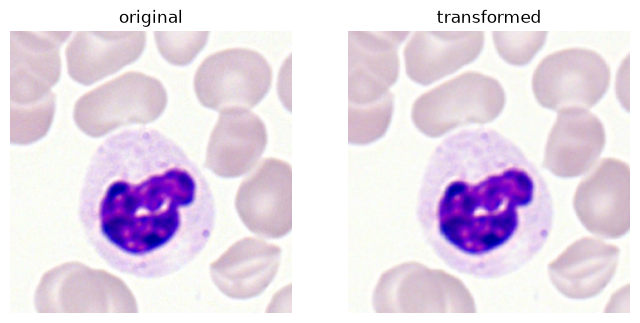

In [20]:
import matplotlib.pyplot as plt

from src.features.transform import Image, v2

path = df[df.dataset == "munich"].sample(1).iloc[0].path
print(path)
with Image.open(path) as img:
    img = img.convert("RGB")
    img_u = v2.functional.pil_to_tensor(img)

out = transform(img_u)
out = (out * dataset_std[:, None, None] + dataset_mean[:, None, None]).clamp(0, 1)

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(to_hwc(img_u))
ax[0].set_title("original")
ax[0].axis("off")
ax[1].imshow(to_hwc(out))
ax[1].set_title("transformed")
ax[1].axis("off")

In [43]:
params = {
    "original": {
        "reinhard_normalizer": None,
        "use_clahe": False,
        "use_jpeg": False,
        "training": False,
    },
    "reinhard+clahe": {
        "reinhard_normalizer": normalizer,
        "use_clahe": True,
        "use_jpeg": False,
        "training": False,
    },
    "transformed": {
        "reinhard_normalizer": normalizer,
        "use_clahe": True,
        "use_jpeg": False,
        "training": True,
    },
    "jpeg": {
        "reinhard_normalizer": normalizer,
        "use_clahe": True,
        "use_jpeg": True,
        "training": True,
    },
}


/var/folders/m_/b04ywwq12g933cgpc9bdd6jm0000gn/T/ipykernel_55605/4212439878.py:21: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  out = (out * dataset_std[:, None, None] + dataset_mean[:, None, None]).clamp(0, 1)


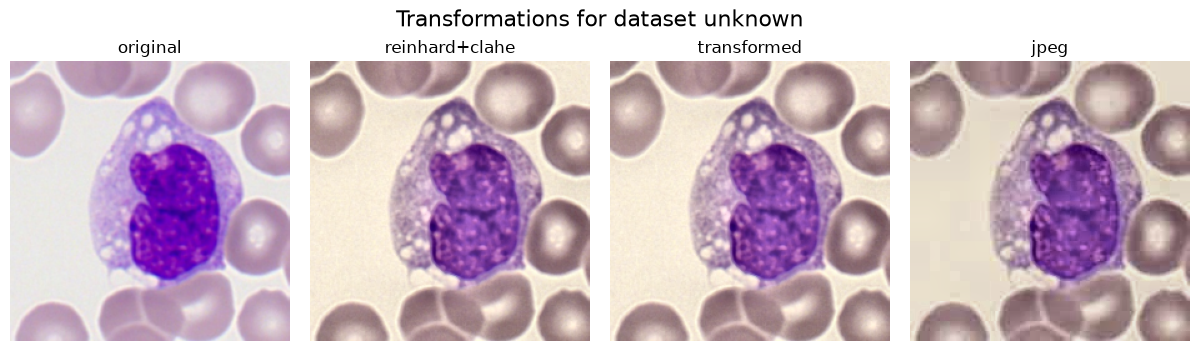

In [ ]:
import math


def display_transforms(img_u=img_u, dataset="unknown"):
    n = len(params)
    fig, axes = plt.subplots(
        1, n, figsize=(3 * n, 3.4), constrained_layout=True
    )  # , figsize=(12, 3 * ncols)
    fig.suptitle(f"Transformations for dataset {dataset}", fontsize=16)
    for ax, (name, param) in zip(axes, params.items()):
        transform = build_transform(
            training=param["training"],
            img_size=(224, 224),
            dataset_mean=dataset_mean,
            dataset_std=dataset_std,
            reinhard_normalizer=param["reinhard_normalizer"],
            use_clahe=param["use_clahe"],
            use_jpeg=param["use_jpeg"],
            jpeg_quality=35,
            p_rotation=0,
        )
        out = transform(img_u)
        out = (out * dataset_std[:, None, None] + dataset_mean[:, None, None]).clamp(0, 1)

        ax.imshow(to_hwc(out))
        ax.set_title(name)
        ax.axis("off")


display_transforms()

In [73]:
%load_ext autoreload

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


/Users/romain/Projects/Liora/Projet/jul26_bds_blood_cells/data/PBC_dataset_normal_DIB/neutrophil/BNE_926497.jpg


/var/folders/m_/b04ywwq12g933cgpc9bdd6jm0000gn/T/ipykernel_55605/2004236849.py:25: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  out = (out * dataset_std[:, None, None] + dataset_mean[:, None, None]).clamp(0, 1)


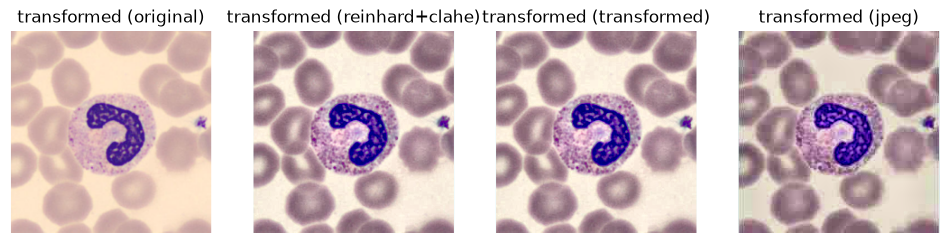

In [50]:
path = df[df.dataset == "barcelona"].sample(1).iloc[0].path
print(path)
with Image.open(path) as img:
    img = img.convert("RGB")
    img_u = v2.functional.pil_to_tensor(img)

display_transforms(img_u=img_u)

/Users/romain/Projects/Liora/Projet/jul26_bds_blood_cells/data/PBC_dataset_normal_DIB/neutrophil/BNE_592314.jpg
/Users/romain/Projects/Liora/Projet/jul26_bds_blood_cells/data/PKG-AML-Cytomorphology_LMU/MON/MON_0439.tiff


/var/folders/m_/b04ywwq12g933cgpc9bdd6jm0000gn/T/ipykernel_55605/4212439878.py:21: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  out = (out * dataset_std[:, None, None] + dataset_mean[:, None, None]).clamp(0, 1)
/var/folders/m_/b04ywwq12g933cgpc9bdd6jm0000gn/T/ipykernel_55605/4212439878.py:21: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  out = (out * dataset_std[:, None, None] + dataset_mean[:, None, None]).clamp(0, 1)


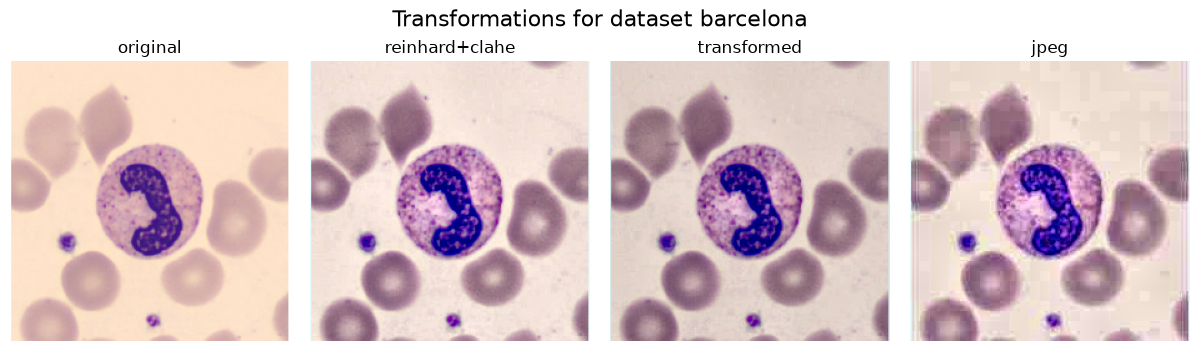

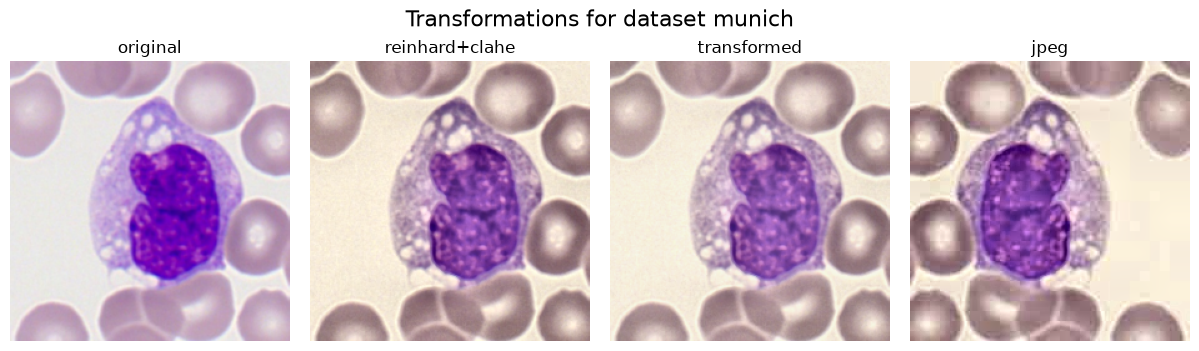

In [70]:
torch.manual_seed(42)

for dataset in ["barcelona", "munich"]:
    path = df[df.dataset == dataset].sample(1, random_state=42).iloc[0].path
    print(path)
    with Image.open(path) as img:
        img = img.convert("RGB")
        img_u = v2.functional.pil_to_tensor(img)

    display_transforms(img_u=img_u, dataset=dataset)


In [75]:
import src.constants
from src.features.dataset import create_dataframe

df = create_dataframe(nb_images=10000, stratify="type_dataset")
print(df.shape)
df.head()

ImportError: cannot import name 'BARCELONA_KEY' from 'src.constants' (/Users/romain/Projects/Liora/Projet/jul26_bds_blood_cells/src/constants.py)